# 🚀 Модуль 3. Урок 4. Эксплораторный анализ данных (EDA) и визуализация в Seaborn & Matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_04_visualization_seaborn_matplotlib.ipynb)

## 📌 Бизнес-контекст и методология
Эксплораторный анализ данных (EDA) позволяет увидеть распределения, тяжелые хвосты и выбросы.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    """Автоматически находит датасет локально или скачивает с GitHub репозитория курса."""
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    print(f"📥 Загрузка {filename} из репозитория курса...")
    urllib.request.urlretrieve(url, filename)
    print(f"✅ Датасет {filename} успешно готов!")
    return filename

# Загрузка ключевых датасетов
customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")


🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных

C:\Users\serge\AppData\Local\Temp\ipykernel_31444\147176874.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


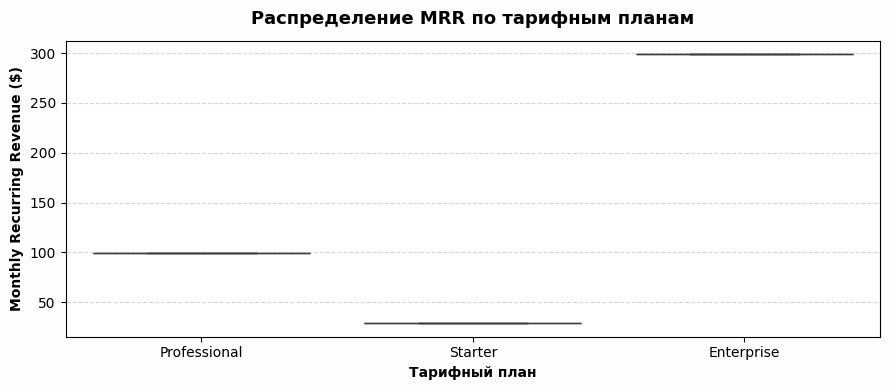

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_saas = pd.read_csv(saas_csv)

plt.figure(figsize=(9, 4), facecolor='#fefefe')
sns.boxplot(
    data=df_saas, 
    x='plan', 
    y='mrr', 
    palette=['#1779ba', '#3adb76', '#ffae00']
)
plt.title("Распределение MRR по тарифным планам", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Тарифный план", fontweight='bold')
plt.ylabel("Monthly Recurring Revenue ($)", fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 🎯 Практическое задание 1: Расчет квантилей MRR для плана Enterprise
Рассчитайте 25-й (Q1), медиану (Q2) и 75-й (Q3) процентили MRR для тарифа Enterprise.

In [3]:
### ВАШ КОД ЗДЕСЬ
ent_mrr = df_saas[df_saas['plan'] == 'Enterprise']['mrr']

q1 = ent_mrr.quantile(0.25)
med = ent_mrr.median()
q3 = ent_mrr.quantile(0.75)

print(f"Enterprise Q1: {q1:.1f}, Med: {med:.1f}, Q3: {q3:.1f}")

assert q3 >= q1 and len(ent_mrr) > 0, "Квантили рассчитаны корректно"
print("✅ Тест успешно пройден!")


Enterprise Q1: 299.0, Med: 299.0, Q3: 299.0
✅ Тест успешно пройден!


### 💡 Почему боксплот надежнее среднего?
Медиана и IQR устойчивы к единичным экстремальным значениям.